In [6]:
import ee   
ee.Initialize(project='mlprojects-510908')
#This is to initialise the google earth engine

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [7]:
lst = (ee.ImageCollection('MODIS/061/MOD11A2')
         .filterDate('2022-07-01', '2022-08-01')
         .select('LST_Day_1km'))

print(lst.size().getInfo())
print(lst.first().getInfo())

4
{'type': 'Image', 'bands': [{'id': 'LST_Day_1km', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [43200, 21600], 'crs': 'SR-ORG:6974', 'crs_transform': [926.6254331383326, 0, -20015109.355797, 0, -926.6254331391667, 10007554.677903]}], 'version': 1779675982326072, 'id': 'MODIS/061/MOD11A2/2022_07_04', 'properties': {'system:time_start': 1656892800000, 'google:max_source_file_timestamp': 1657873414000, 'num_tiles': 317, 'system:footprint': {'type': 'LinearRing', 'coordinates': [[-180, -90], [180, -90], [180, 90], [-180, 90], [-180, -90]]}, 'system:time_end': 1657584000000, 'system:asset_size': 984801986, 'system:index': '2022_07_04'}}


In [8]:
# Load the Country borders table hosted on Earth Engine
countries = ee.FeatureCollection('USDOS/LSIB_SIMPLE/2017')
uk = countries.filter(ee.Filter.eq('country_na', 'United Kingdom'))
#Ask how many rows matched? Should just be one.
print(uk.size().getInfo())

#ask the server for the shapes bounding box
print(uk.geometry().bounds().getInfo())

1
{'geodesic': False, 'type': 'Polygon', 'coordinates': [[[-13.690860748704889, 49.902084326114], [1.7658056360502927, 49.902084326114], [1.7658056360502927, 60.847084071722314], [-13.690860748704889, 60.847084071722314], [-13.690860748704889, 49.902084326114]]]}


In [9]:
# Draw 2000 random locations that fall inside the uk polygon
#seed=42 makes the draw repeatable, so tou get the same points every time

points = ee.FeatureCollection.randomPoints(
    region=uk.geometry(),
    points= 2000,
    seed=42
)

#count them to confirm we got what we asked for 
print(points.size().getInfo())
print(points.first().getInfo())

2000
{'type': 'Feature', 'geometry': {'type': 'Point', 'coordinates': [0.11948981352419201, 50.94608390049139]}, 'id': '0', 'properties': {}}


In [2]:
import geemap
import pandas as pd


In [13]:
lst_mean = lst.mean()
lst_c = lst_mean.multiply(0.02).subtract(273.15)
lst_uk= lst_c.clip(uk)
vis = {'min': 10, 'max': 35, 'palette': ['blue', 'cyan', 'orange', 'red']}
m = geemap.Map()
m.centerObject(uk, 5) #zoom into the uk
m.addLayer(lst_uk, vis, 'Mean LST July 2022 (C)') #temperature layer
m.addLayer(points, {'colour': 'black'}, 'Sample Points') #my 2000 points
m

Map(center=[54.0257825222589, -2.779718210465655], controls=(WidgetControl(options=['position', 'transparent_b…

In [14]:
valid = lst.count()
vis_n = {'min': '0', 'max': 4, 'palette': ['white', 'yellow', 'green']}
m.addLayer(valid.clip(uk), vis_n, 'Valid images (count)')
m

Map(bottom=10949.0, center=[53.166533500950905, -0.7415771484375], controls=(WidgetControl(options=['position'…

In [15]:
times = lst.aggregate_array('system:time_start').getInfo() # ask the server for each image's start time (milliseconds since 1970)
print([pd.to_datetime(t, unit='ms').date() for t in times]) # convert each to a readable date and print the list


[datetime.date(2022, 7, 4), datetime.date(2022, 7, 12), datetime.date(2022, 7, 20), datetime.date(2022, 7, 28)]


In [16]:
dec = ee.ImageCollection('MODIS/061/MOD11A2').filterDate('2021-12-01', '2022-01-10')
t = dec.aggregate_array('system:time_start').getInfo()
print([pd.to_datetime(x, unit='ms').date() for x in t])

[datetime.date(2021, 12, 3), datetime.date(2021, 12, 11), datetime.date(2021, 12, 19), datetime.date(2021, 12, 27), datetime.date(2022, 1, 1), datetime.date(2022, 1, 9)]


In [18]:
ndvi = (ee.ImageCollection('MODIS/061/MOD13A2')
                           .filterDate('2022-06-01', '2022-08-31')
                           .select('NDVI'))
tn = ndvi.aggregate_array('system:time_start').getInfo()
print([pd.to_datetime(x, unit='ms').date() for x in tn])

[datetime.date(2022, 6, 10), datetime.date(2022, 6, 26), datetime.date(2022, 7, 12), datetime.date(2022, 7, 28), datetime.date(2022, 8, 13), datetime.date(2022, 8, 29)]


In [19]:
sample = lst_c.sampleRegions(
    collection = points,
    scale = 1000,
    geometries = True
)
print(sample.size().getInfo())
print(sample.first().getInfo())

1983
{'type': 'Feature', 'geometry': {'geodesic': False, 'type': 'Point', 'coordinates': [0.12127256335613541, 50.947951338838664]}, 'id': '0_0', 'properties': {'LST_Day_1km': 28.44500000000005}}


In [21]:
points = points.map(lambda f: f.set({
    'pid': f.id(),
    'lon': f.geometry().coordinates().get(0),
    'lat': f.geometry().coordinates().get(1)
}))

# Sample the July mean LST at the points again; now each row carries pid, lon and lat
sample = lst_c.sampleRegions(collection=points, scale=1000)

# Bring the table to your laptop as a pandas DataFrame (about 2000 rows, so getInfo-sized is fine)
features = sample.getInfo()['features']
df = pd.DataFrame([f['properties'] for f in features])

print(df.shape)
print(df.head())
print(df['LST_Day_1km'].describe())



(1983, 4)
   LST_Day_1km        lat       lon pid
0    28.445000  50.946084  0.119490   0
1    32.043333  52.117576 -1.990680   1
2    22.735000  57.234761 -3.185914   2
3    21.723333  51.976955 -4.529788   3
4    23.936667  56.580776 -2.628107   4
count    1983.000000
mean       25.080930
std         5.178121
min         8.576667
25%        21.024167
50%        24.996667
75%        29.432500
max        39.200000
Name: LST_Day_1km, dtype: float64


In [22]:
print(df.nlargest(5, 'LST_Day_1km'))
print(df.nsmallest(5, 'LST_Day_1km'))

      LST_Day_1km        lat       lon   pid
1799    39.200000  52.130731 -0.454060  1816
1593    37.923333  52.650348  1.281582  1609
885     36.995000  51.510241 -0.373738   897
1875    36.610000  51.527442  0.145772  1892
625     36.370000  51.510318 -0.584849   632
      LST_Day_1km        lat       lon   pid
1583     8.576667  57.379031 -5.694786  1599
181      9.765000  58.997774 -3.162344   182
879     11.660000  57.832656 -7.027187   891
116     12.365000  60.715273 -0.958504   117
1547    12.476667  58.963958 -2.732235  1562


In [30]:
summer22 = (ee.ImageCollection('MODIS/061/MOD11A2')
            .filterDate('2022-06-01', '2022-09-01')
            .select('LST_Day_1km'))

print(summer22.size().getInfo())
t = summer22.aggregate_array('system:time_start').getInfo()
print([pd.to_datetime(x, unit='ms').date() for x in t])

12
[datetime.date(2022, 6, 2), datetime.date(2022, 6, 10), datetime.date(2022, 6, 18), datetime.date(2022, 6, 26), datetime.date(2022, 7, 4), datetime.date(2022, 7, 12), datetime.date(2022, 7, 20), datetime.date(2022, 7, 28), datetime.date(2022, 8, 5), datetime.date(2022, 8, 13), datetime.date(2022, 8, 21), datetime.date(2022, 8, 29)]


In [31]:
import numpy as np
points_sub = points.limit(200)

def sample_one(img):
    date = img.date().format('YYYY-MM-dd')
    celcius = img.multiply(0.02).subtract(273.15)
    celcius = celcius.unmask(-9999)
    rows = celcius.sampleRegions(collection = points_sub, scale = 1000)
    return rows.map(lambda f: f.set('date', date))

# Apply it to every composite; the result is 12 small tables, and flatten() stacks them into one
table = ee.FeatureCollection(summer22.map(sample_one)).flatten()

print(table.size().getInfo())
rows = table.getInfo()['features']
df22 = pd.DataFrame(f['properties'] for f in rows)
df22['LST_Day_1km'].replace(-9999, np.nan)
print(df22.shape)



2400
(2400, 5)


In [32]:
df22['LST_Day_1km'] = df22['LST_Day_1km'].replace(-9999, np.nan)
print(df22['LST_Day_1km'].isna().sum())   
print(df22['LST_Day_1km'].isna().groupby(df22['date']).sum())
print(df22['LST_Day_1km'].describe())  
print(df22.head())


365
date
2022-06-02     24
2022-06-10     30
2022-06-18      7
2022-06-26     65
2022-07-04      9
2022-07-12      8
2022-07-20    122
2022-07-28     26
2022-08-05     10
2022-08-13      7
2022-08-21     26
2022-08-29     31
Name: LST_Day_1km, dtype: int64
count    2035.000000
mean       23.982226
std         5.840169
min         2.690000
25%        19.800000
50%        23.410000
75%        28.090000
max        39.590000
Name: LST_Day_1km, dtype: float64
   LST_Day_1km        date        lat       lon pid
0        25.03  2022-06-02  50.946084  0.119490   0
1        23.15  2022-06-02  52.117576 -1.990680   1
2        22.81  2022-06-02  57.234761 -3.185914   2
3        19.61  2022-06-02  51.976955 -4.529788   3
4        22.59  2022-06-02  56.580776 -2.628107   4


In [34]:
era = ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')   # ERA5-Land daily weather, pixels about 11 km wide

t = ee.Date('2022-07-04')
win = era.filterDate(t.advance(-8, 'day'), t)

print(win.size().getInfo())
d = win.aggregate_array('system:time_start').getInfo()
print([pd.to_datetime(x, unit = 'ms').date() for x in d])


8
[datetime.date(2022, 6, 26), datetime.date(2022, 6, 27), datetime.date(2022, 6, 28), datetime.date(2022, 6, 29), datetime.date(2022, 6, 30), datetime.date(2022, 7, 1), datetime.date(2022, 7, 2), datetime.date(2022, 7, 3)]


In [36]:
sm = (win.select('volumetric_soil_water_layer_1')
      .mean()
      .unmask(-9999))

sm_rows = sm.sampleRegions(collection=points, scale = 11132)
sm_df = pd.DataFrame([f['properties'] for f in sm_rows.getInfo()['features']])
sm_df = sm_df.replace(-9999, np.nan)

print(sm_df.shape)
print(sm_df['volumetric_soil_water_layer_1'].describe())
print(sm_df['volumetric_soil_water_layer_1'].nunique())


(2000, 4)
count    1867.000000
mean        0.341443
std         0.121744
min         0.109932
25%         0.266743
50%         0.322815
75%         0.374015
max         0.730742
Name: volumetric_soil_water_layer_1, dtype: float64
1410


(200, 3)
                               LST_Day_1km  volumetric_soil_water_layer_1
LST_Day_1km                       1.000000                      -0.333643
volumetric_soil_water_layer_1    -0.333643                       1.000000


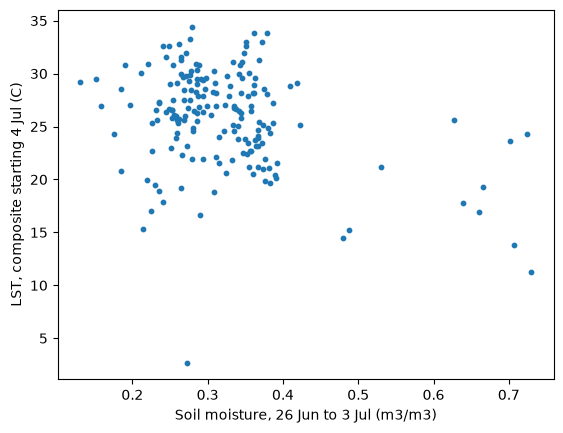

In [39]:
import matplotlib.pyplot as plt

lst_0704 = df22[df22['date'] == '2022-07-04'][['pid', 'LST_Day_1km']]
check = lst_0704.merge(sm_df[['pid', 'volumetric_soil_water_layer_1']], on= 'pid')
print(check.shape)
print(check.corr(numeric_only=True))

plt.scatter(check['volumetric_soil_water_layer_1'], check['LST_Day_1km'], s=10)
plt.xlabel('Soil moisture, 26 Jun to 3 Jul (m3/m3)')
plt.ylabel('LST, composite starting 4 Jul (C)')
plt.show()

In [ ]:
def era_window(t):
    win = era.filterDate(t.advance(-8, 'day'), t)
    sm = win.select('volumetric_soil_water_layer_1').mean().rename('soil_moisture')
    precip = win.select('total_precipitation_sum').sum().rename('precip_8d')
    dew = win.select('dewpoint_temperature_2m').mean().rename('dewpoint')
    rad = win.select('surface_solar_radiation_downwards_sum').sum().rename('solar_8d')
    return sm.addBands([precip, dew, rad])

In [42]:
t = ee.Date('2022-07-04')
era_img = era_window(t).unmask(-9999)
rows = era_img.sampleRegions(collection=points, scale = 11132)
era_df = pd.DataFrame([f['properties'] for f in rows.getInfo()['features']])
era_df = era_df.replace(-9999, np.nan)

print(era_df.shape)
print(era_df.describe().T)

(2000, 7)
                count          mean           std           min           25%  \
dewpoint       1867.0  2.827151e+02  6.391981e-01  2.799068e+02  2.823423e+02   
lat            2000.0  5.390391e+01  2.301990e+00  5.001101e+01  5.199996e+01   
lon            2000.0 -2.737305e+00  2.002142e+00 -8.087054e+00 -4.117703e+00   
precip_8d      1867.0  2.984899e-02  1.594396e-02  6.637065e-03  1.632923e-02   
soil_mositure  1867.0  3.414435e-01  1.217442e-01  1.099316e-01  2.667428e-01   
solar_8d       1867.0  1.433806e+08  1.381881e+07  1.133538e+08  1.337358e+08   

                        50%           75%           max  
dewpoint       2.827276e+02  2.831407e+02  2.847162e+02  
lat            5.336541e+01  5.570689e+01  6.082187e+01  
lon           -2.779736e+00 -1.286258e+00  1.720731e+00  
precip_8d      2.691704e-02  4.045688e-02  8.551128e-02  
soil_mositure  3.228151e-01  3.740149e-01  7.307417e-01  
solar_8d       1.463259e+08  1.518237e+08  1.886411e+08  
